<a href="https://colab.research.google.com/github/KangKyungHwa/DSMH_2/blob/main/___11_19/11%EC%9B%94_19%EC%9D%BC_%EB%B9%85%EB%8D%B0%EC%9D%B4%ED%84%B0%EB%B6%84%EC%84%9D%EC%97%B0%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone 'https://'github.com/KangKyungHwa/DSMH_2/''

# 1. 나눔고딕 폰트 설치
!sudo apt-get update -qq
!sudo apt-get install -y fonts-nanum-extra -qq

# 2. 시스템 폰트 캐시 업데이트
!sudo fc-cache -fv

# 3. Matplotlib 폰트 캐시 삭제
!rm -rf ~/.cache/matplotlib


import matplotlib.pyplot as plt
from matplotlib import font_manager, rc

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['font.size'] = 11

print("현재 Matplotlib 폰트 설정:", plt.rcParams['font.family']) #현재 설치된 폰트 확인


Cloning into 'DSMH_2'...
remote: Enumerating objects: 230, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 230 (delta 26), reused 2 (delta 2), pack-reused 179 (from 1)
Receiving objects: 100% (230/230), 23.57 MiB | 11.36 MiB/s, done.
Resolving deltas: 100% (89/89), done.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 2.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previous

## 1.빅데이터 사례분석 연습 --> 기본 탐색 및 데이터 전처리 과정 (11월12일 분석에 이어서)

### (1)각종 기프트 세트를 취급하는 온라인 몰의 전자상거래 데이터 분석
### (2)분석방법 : 통계모형을 사용하지 않고 기본탐색 및 데이터 전처리, 기술적 분석, 고객분류기법중 하나인 RFM 분석

####InvoiceNo : 각 거래에 고유하게 부여된 6자리 정수 (문자 C로 시작하면 취소를 나타냄)
####StockCode  : 아이템 코드, 문자변수       
####Description: 아이템 이름, 문자변수
####Quantity   : 거래 아이템 수량, 숫자변수  
####InvoiceDate :거래 실행 날짜
####UnitPrice :단가(파운드), 숫자
####Customer ID :고객 ID
####Country : 국가명



##2. 데이터 수집 및 전처리

#### (1)💻 내 PC에서 파일 불러오기

In [2]:
# 시각화 그래프(그림)를 노트북 내부(inline)에 바로 출력하도록 함
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files


# 1. 내 PC에서 파일 직접 업로드
uploaded = files.upload()

# 2. 업로드된 파일을 pandas DataFrame으로 읽기

file_name = "online_retail.xlsx"
retail_df = pd.read_excel(file_name)

Saving online_retail.xlsx to online_retail.xlsx


####(2) 데이터 정보확인하기

In [3]:
print("=== 데이터 기본 정보 ===")
print(retail_df.info())

print("\n=== 데이터 기술통계 요약 ===")
display(retail_df.describe())

=== 데이터 기본 정보 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None

=== 데이터 기술통계 요약 ===


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


####(3)숫자형 변수 (Quantity, UnitPrice에 음수 값이 있으므로 --> 정리할 필요가 있음 : 거래가 취소된 경우 음수값으로 처리했음)
##### 취소된 거래는 InvoiceNo가 "C" 로 시작되어 있으므로 'C'를 포함하고 있는 InvoiceNo 항목을 찾아본다

In [4]:

cancelled = retail_df[retail_df['InvoiceNo'].astype(str).str.contains('C')]
print(cancelled.head())
print('\n\n 취소된 거래 :', len(cancelled))


    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  


 취소된 거래 : 9288


####(4) InvoiceNo에 "C"를 포함한 거래중에서 Quantity가 0 이상인 행이 있는지 확인해 본다

In [5]:
cancelled[cancelled['Quantity']>0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


####(5) Quantity가 음수이거나 0인 거래 중 일부는 취소된 거래에 속하지 않는 경우가 있다(즉, InvoiceNo에 "C"가 쓰여있지 않은경우). 이를 확인해 보자.(취소가 되지는 않았지만 음수이거나 0인 거래 찾아보기)

In [6]:
print("취소된 거래 건수:", len(cancelled))
print("InvoiceNo에 'C'를 포함하지 않으면서 Quantity가 음수이거나 0인 거래 건수:",
retail_df[retail_df['Quantity']<=0]['Quantity'].count())


취소된 거래 건수: 9288
InvoiceNo에 'C'를 포함하지 않으면서 Quantity가 음수이거나 0인 거래 건수: 10624


####(6) 단가(UnitPrice)가 0인 거래 찾아보기  

In [7]:
unit_zero=retail_df[retail_df['UnitPrice']==0]
print(len(unit_zero),'개')

2515 개


####(7) 단가(UnitPrice)가 마이너스인 거래 찾아보기  

In [8]:
unit_minus=retail_df[retail_df['UnitPrice']<0]
print(unit_minus.head())
print('\n',len(unit_minus),'개')

       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
299983   A563186         B  Adjust bad debt         1 2011-08-12 14:51:00   
299984   A563187         B  Adjust bad debt         1 2011-08-12 14:52:00   

        UnitPrice  CustomerID         Country  
299983  -11062.06         NaN  United Kingdom  
299984  -11062.06         NaN  United Kingdom  

 2 개


####(8) 취소되지 않은 거래 , 즉 InvoiceNo가 'C'로 시작하지 않은 거래 중 일부 Quantity가 음수이거나 0 이면서 UnitPice도 0인 거래

In [9]:
d = retail_df[~retail_df['InvoiceNo'].astype(str).str.contains('C')]

print("취소되지 않은 거래 중 Quantity가 0이거나 음수인 거래 건수:", len(d[d['Quantity']<=0]))
print("UnitPrice가 0이면서 Quantity가 0이거나 음수인 거래 건수:",
len(d[(d['Quantity']<=0) & (d['UnitPrice']==0)]))

취소되지 않은 거래 중 Quantity가 0이거나 음수인 거래 건수: 1336
UnitPrice가 0이면서 Quantity가 0이거나 음수인 거래 건수: 1336


####(9) 데이터의 대략적인 탐색 후 실제 분석에 사용할 데이터를 추출해 보기 : UnitPrice가 양수이면서 Quantity도 양수인 거래만 사용


In [10]:
# 최종적으로 사용되어야할 데이터 추출
df = retail_df[(retail_df['UnitPrice']>0) & (retail_df['Quantity']>0)]
print("\n데이터 행의 개수:", df.shape[0])
print("\n데이터 열의 개수(항목):", df.shape[1])


데이터 행의 개수: 530104

데이터 열의 개수(항목): 8


####(10) Index 번호 다시 매기기 --> 분석에 사용할 데이터의 Index

In [11]:
df = df.reset_index()
df = df.drop('index', axis =1) # 기존의 인덱스 삭제
print (df)

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
530099    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
530100    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
530101    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
530102    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
530103    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  CustomerID         Country  
0      

####(11) 중복된 데이터 찾기

In [12]:
print("중복 기록된 거래 건수 :", len(df[df.duplicated()]))


중복 기록된 거래 건수 : 5226


####(12) 중복된 데이터 삭제

In [13]:
#inplace=True: 원본 데이터프레임에서 중복된 데이터 삭제함
df.drop_duplicates(inplace=True)

####(12_1) 중복된 데이터 삭제되었는지 확인해 보기

In [14]:
print("중복 기록된 거래 건수 :", len(df[df.duplicated()]))

중복 기록된 거래 건수 : 0


####(13) CustomerID가 기록되지 않은 데이터도 제거한다
위 (2)에서 describe()함수로 확인한 결과 CustomerID는 406829건 으로 나타남

In [15]:
df = df.dropna(subset = ['CustomerID'])
print(df)

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
530099    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
530100    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
530101    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
530102    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
530103    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  CustomerID         Country  
0      

####(14) 새로 만든 데이터세트에 대해 다시 한 번 결측값 점검해 보기

In [16]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 530103
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[ns]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.0+ MB
None


####(15) 분석에 편리하도독 Discription 항목의 대문자를 모두 소문자로 변환해 준다

In [17]:
df = df.assign(Description = df['Description'].str.lower())
print(df.head(3))

  InvoiceNo StockCode                         Description  Quantity  \
0    536365    85123A  white hanging heart t-light holder         6   
1    536365     71053                 white metal lantern         6   
2    536365    84406B      cream cupid hearts coat hanger         8   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  


####(16) Discription 고유값 개수 알아보기 : 매출제품

In [18]:
print(" Description 고유값 개수:", len(df['Description'].unique()),'의 품목 판매중')

 Description 고유값 개수: 3877 의 품목 판매중


####(17) Description에서 마침표 제거 하기 : 모든 알파벳, 숫자, 언더스코어, 공백을 제외한 모든 string 삭제

In [19]:
a = df['Description'].replace(to_replace=r'[^\w\s]', value='', regex=True)

#regex: 정규표현식(텍스트 문자열을 검색하고 조작하는 데 편리)
#r에 값들을 value의 공백으로 대체
# r  : 정규표현식
# ^  : 제외 한다는 뜻
# \w : 알파벳 대소문자, 숫자, 밑줄
# \s : 모든 공백(스페이스바, 탭, 줄바꿈, 엔터등)

#새로운 Deprecation항목을 추가하여 a 의 값을 넣어 줌
df =df.assign(Deprecation = a)

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   white hanging heart t-light holder         6   
1    536365     71053                  white metal lantern         6   
2    536365    84406B       cream cupid hearts coat hanger         8   
3    536365    84029G  knitted union flag hot water bottle         6   
4    536365    84029E       red woolly hottie white heart.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   

                           Deprecation  
0    white hanging heart tlight holder  
1                  white metal lantern  
2       cream cupid hearts coat hanger  
3  knitted union f

####(18) Descrioption 문자열 정리로 변한 데이타의 고유갯수 나타내기 (변화는 없음)

In [20]:
print(" Description 고유값 개수:", len(df['Description'].unique()))

 Description 고유값 개수: 3877


####(19)날짜처리  : InvoiceDate의 연도, 월, 연월, 요일, 시간을 따로 분리해보기

In [21]:
df['month']=df['InvoiceDate'].dt.month
df['year']=df['InvoiceDate'].dt.year
df['WeekDay']=df['InvoiceDate'].dt.day_name()
df['year_month']=df['InvoiceDate'].dt.strftime('%Y-%m')
df['hour']=df['InvoiceDate'].dt.hour
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   white hanging heart t-light holder         6   
1    536365     71053                  white metal lantern         6   
2    536365    84406B       cream cupid hearts coat hanger         8   
3    536365    84029G  knitted union flag hot water bottle         6   
4    536365    84029E       red woolly hottie white heart.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   

                           Deprecation  month  year    WeekDay year_month  \
0    white hanging heart tlight holder     12  2010  Wednesday    2010-12   
1                  white met

 #### (20)판매액 변수 만들기(Quantity *UnitPrie )

In [22]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print(df.head())  #수익 항목이 추가된 것을 알수 있다

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   white hanging heart t-light holder         6   
1    536365     71053                  white metal lantern         6   
2    536365    84406B       cream cupid hearts coat hanger         8   
3    536365    84029G  knitted union flag hot water bottle         6   
4    536365    84029E       red woolly hottie white heart.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   

                           Deprecation  month  year    WeekDay year_month  \
0    white hanging heart tlight holder     12  2010  Wednesday    2010-12   
1                  white met

###3. 기술적 분석

####(1)연월별 거래건수  (InvoiceNo가 월별 몇 개인지 알아보기)

In [43]:
monthly= pd.DataFrame(df.groupby(['year_month'])['InvoiceNo'].count()).reset_index()

print(monthly)

   year_month  InvoiceNo
0     2010-12      25670
1     2011-01      20988
2     2011-02      19706
3     2011-03      26870
4     2011-04      22433
5     2011-05      28073
6     2011-06      26926
7     2011-07      26580
8     2011-08      26790
9     2011-09      39669
10    2011-10      48793
11    2011-11      63168
12    2011-12      17026


####(1_1) 연월별 거래건수 그래프 그리기

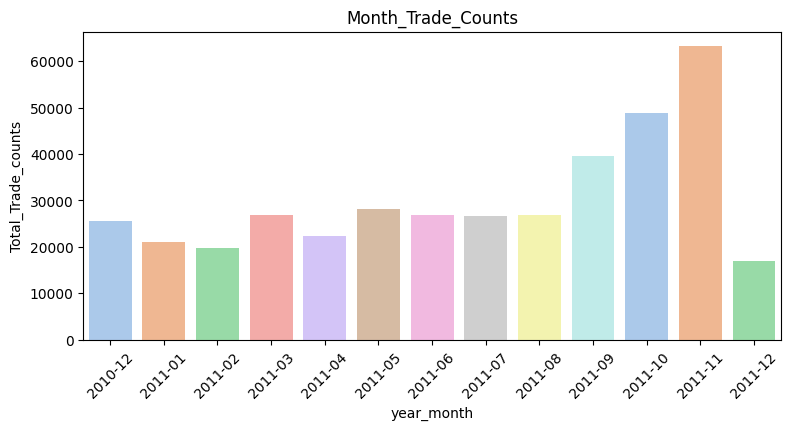

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.size'] = 10
plt.figure(figsize=(9,4))

# 년월(year_month) 컬럼 자체를 hue에 전달하여, 각 월마다 알록달록 다른 색으로 채우기
sns.barplot(x='year_month', y='InvoiceNo', data=monthly, hue='year_month', palette='pastel', legend=False)

plt.xlabel('year_month')
plt.ylabel('Total_Trade_counts')
plt.title('Month_Trade_Counts')

# 가로축 레이블을 45도 비스듬하게 회전
plt.xticks(rotation=45)
plt.show()

####(2) 요일별 거래건수

In [46]:
Weekly= pd.DataFrame(df.groupby(['WeekDay'])['InvoiceNo'].count())
Weekly=Weekly.reindex(['Monday','Tuesday','Wednesday','Thursday',
'Friday','Saturday','Sunday']).reset_index()
print(Weekly)

     WeekDay  InvoiceNo
0     Monday    64231.0
1    Tuesday    65744.0
2  Wednesday    68040.0
3   Thursday    79243.0
4     Friday    54222.0
5   Saturday        NaN
6     Sunday    61212.0


####(2_1) 요일별 거래건수 그래프 그리기

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52509 (\N{HANGUL SYLLABLE CONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

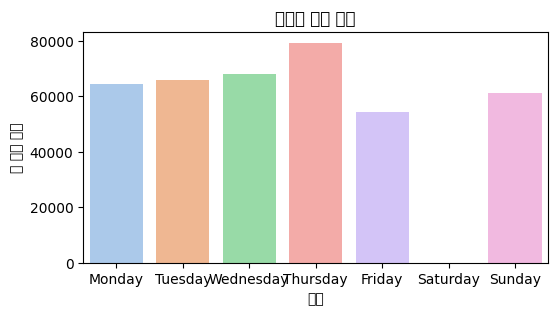

In [47]:
plt.figure(figsize=(6,3))

# 요일(WeekDay) 컬럼 자체를 hue에 전달하여, 각 요일마다 알록달록 다른 색으로 채우기
sns.barplot(x='WeekDay', y='InvoiceNo', data=Weekly, hue='WeekDay', palette='pastel', legend=False)

plt.xlabel('요일')
plt.ylabel('총 거래 건수')
plt.title('요일별 거래 건수')
plt.show()

####(3) 시간별 거래건수

In [50]:
hourly=pd.DataFrame(df.groupby(['hour'])['InvoiceNo'].count()).reset_index()
print(hourly)

    hour  InvoiceNo
0      6          1
1      7        379
2      8       8687
3      9      21927
4     10      37773
5     11      48365
6     12      70938
7     13      63019
8     14      53251
9     15      44790
10    16      23715
11    17      12941
12    18       2895
13    19       3233
14    20        778


####(3_1) 시간별 거래건수 그래프 그리기

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52509 (\N{HANGUL SYLLABLE CONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

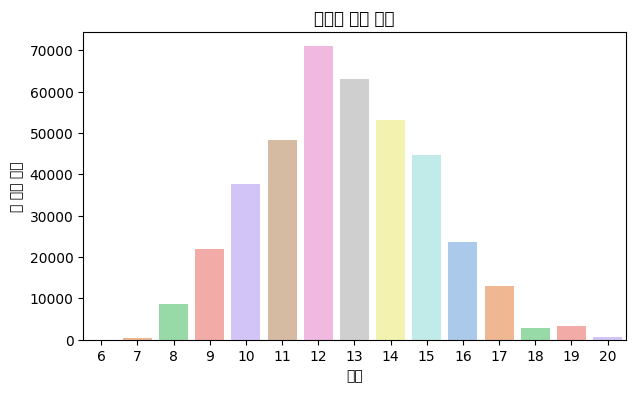

In [51]:
plt.figure(figsize=(7,4))

# 요일(WeekDay) 컬럼 자체를 hue에 전달하여, 각 요일마다 알록달록 다른 색으로 채우기
sns.barplot(x='hour', y='InvoiceNo', data=hourly, hue='hour', palette='pastel', legend=False)
plt.xlabel('시간')
plt.ylabel('총 거래 건수')
plt.title('시간별 거래 건수')
plt.show()

####(4) 판매액이 가장 많은 연월 찾기

In [29]:
monthly1= pd.DataFrame(df.groupby(['year_month'])['Revenue'].sum()).reset_index()

print(monthly1)

   year_month      Revenue
0     2010-12   570422.730
1     2011-01   568101.310
2     2011-02   446084.920
3     2011-03   594081.760
4     2011-04   468374.331
5     2011-05   677355.150
6     2011-06   660046.050
7     2011-07   598962.901
8     2011-08   644051.040
9     2011-09   950690.202
10    2011-10  1035642.450
11    2011-11  1156205.610
12    2011-12   517190.440


####(5) 판매액이 가장 많은 연월  그래프 그리기

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52509 (\N{HANGUL SYLLABLE CONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54032 (\N{HANGUL SYLLABLE PAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47588 (\N{HANGUL SYLLABLE MAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50529 (\N{HANGUL SYLLABLE AEG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

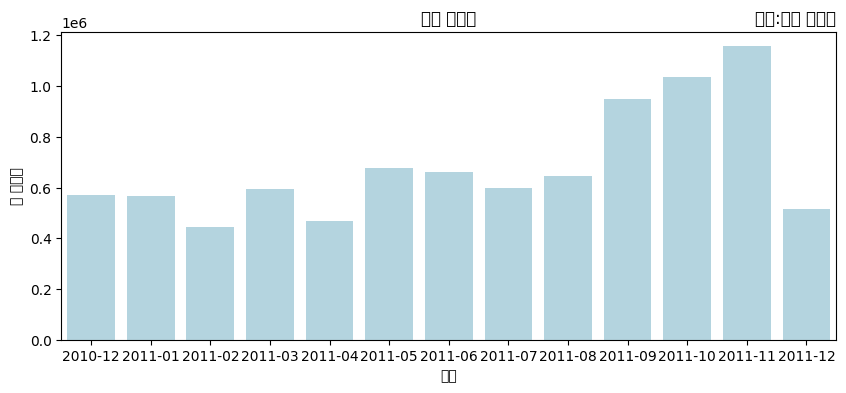

In [30]:
plt.figure(figsize=(10,4))

sns.barplot(x='year_month', y='Revenue', data=monthly1, color='lightblue')
plt.xlabel('연월')
plt.ylabel('총 판매액')
plt.title('월별 판매액')
plt.title ('단위:백만 파운드', loc='right')
plt.show()

# 표의 좌측 위의 1e6 의미: 예 -> 2.3e6(또는 2.3e+6)   2.3*1e6 즉 2.3*1,000,000 =2,300,000 을 의미
                        #  예 -> 2.3e-6     예: 2.3*10-2 즉 2.3*0.01 =0.023 을 의미

####(6) 제품 가격 분석

In [31]:
pd.DataFrame(df['UnitPrice']).describe()
# 대부분의 판매상품 가격이 저렴하다는것을 알 수 있음


,UnitPrice
count,392692.000000
mean,3.125914
std,22.241836
min,0.001000
25%,1.250000
50%,1.950000
75%,3.750000
max,8142.750000


####(7)단가가 50 파운드 이상인 제품 찾아보기

In [32]:
df[df['UnitPrice']>50]['Description'].unique().tolist()
# 소박한 17서랍 찬장
# 빈티지 우체국 캐비닛
# 빈티지 레드 주방 캐비닛
# 셔터가 있는 리젠시 미러
# 러브 시트 앤티크 화이트 메탈
# 빈티지 블루 주방 캐비닛
# 학교 책상과 의자
# 체트트 천연목 20단 서랍
# 운반대
# 장식용 걸이형 선반 유닛
# 매뉴얼
# 우표
# 소풍 바구니 고리버들 60개
# 닷컴 우표

['rustic  seventeen drawer sideboard',
 'vintage post office cabinet',
 'vintage red kitchen cabinet',
 'regency mirror with shutters',
 'love seat antique white metal',
 'vintage blue kitchen cabinet',
 'school desk and chair ',
 'chest natural wood 20 drawers',
 'carriage',
 'decorative hanging shelving unit',
 'manual',
 'postage',
 'picnic basket wicker 60 pieces',
 'dotcom postage']

####(8)고가상품의 가격 분포 알아보기

<Figure size 1000x400 with 0 Axes>

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48128 (\N{HANGUL SYLLABLE MIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

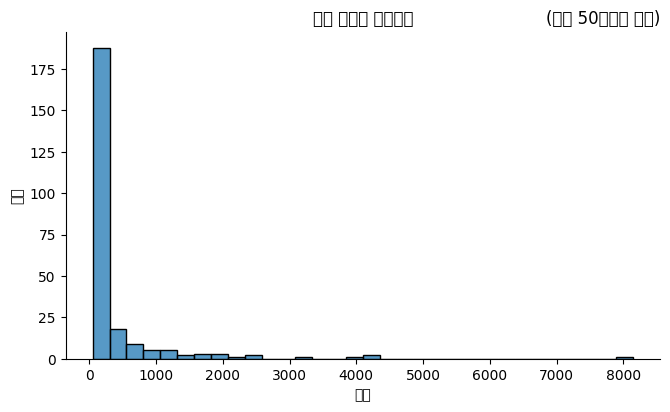

In [33]:
plt.figure(figsize=(10,4))

sns.displot(df[df['UnitPrice']>50]['UnitPrice'], height=4, aspect=1.7)
plt.xlabel('단가')
plt.ylabel('밀도')
plt.title('고가 상품의 가격분포')
plt.title ('(단가 50파운드 이상)', loc='right')
plt.show()

####(9)거래 빈도가 가장 높은 제품 알아보기

In [34]:
prod= pd.DataFrame(df['Description'].value_counts().head(10))
prod= prod.set_axis(['freq'], axis=1).rename_axis('Description').reset_index()
print(prod)

                          Description  freq
0  white hanging heart t-light holder  2016
1            regency cakestand 3 tier  1713
2             jumbo bag red retrospot  1615
3       assorted colour bird ornament  1395
4                       party bunting  1389
5             lunch bag red retrospot  1303
6   set of 3 cake tins pantry design   1152
7                             postage  1099
8             lunch bag  black skull.  1078
9     pack of 72 retrospot cake cases  1050


####(9_1)거래 빈도가 가장 높은 제품 그래프 그리기

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48712 (\N{HANGUL SYLLABLE BIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

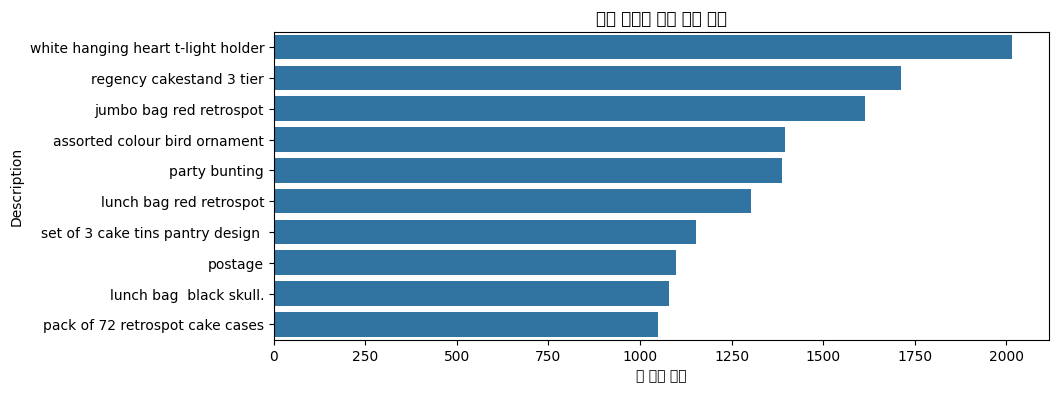

In [35]:
plt.figure(figsize=(10,4))

sns.barplot(x='freq', y='Description', data = prod.sort_values(by='freq', ascending=False))
plt.title('거래 빈도가 가장 높은 품목')
plt.xlabel('총 거래 건수')
plt.show()

####(10)나라별 거래 알아보기

In [36]:
customer_country = df[['Country','CustomerID']].drop_duplicates()
print(customer_country['Country'].value_counts(normalize =True).head(10))

print('\n\n',"거래는", len(df['Country'].unique()), "개국 과 이루어짐")

#나라이름이 명시되지 않은 경우
print("나라 이름이 \"Unspecified\"로 표기된 거래 건수 : ", len(df[df['Country']=='Unspecified']))


Country
United Kingdom    0.901979
Germany           0.021629
France            0.020018
Spain             0.006903
Belgium           0.005752
Switzerland       0.004832
Portugal          0.004372
Italy             0.003221
Finland           0.002761
Austria           0.002531
Name: proportion, dtype: float64


 거래는 37 개국 과 이루어짐
나라 이름이 "Unspecified"로 표기된 거래 건수 :  241
